In [ ]:
import random
import os
from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from keras import models, layers, callbacks
from sklearn.preprocessing import StandardScaler
from imblearn.combine import SMOTEENN
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import register_keras_serializable

In [2]:
print(tf.__version__)

2.20.0


In [3]:
tf.keras.mixed_precision.set_global_policy('float64')

In [ ]:
current_dir = Path.cwd()

In [2]:
def set_reproducibility(seed=42):
    # 1. Fijar semilla en Python core
    os.environ['PYTHONHASHSEED'] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    keras.utils.set_random_seed(seed)
set_reproducibility()

In [4]:
tf.random.set_seed(42)

In [ ]:
protbert_embed_dim = 1024
features_dim = 887
latent_dim = 128
T = 20
S = 20
encoder_dir = str(current_dir.parent / 'models/vae_enc_smoteen.keras')
classifier_dir = str(current_dir.parent / 'models/vae_classifier_smoteen.keras')

In [ ]:
X_train_emb = np.load(str(current_dir.parent / 'datasets/pre_processed/train_emb.npy'))
X_train_feat = np.load(str(current_dir.parent / 'datasets/pre_processed/train_feat.npy'))
X_valid_emb = np.load(str(current_dir.parent / 'datasets/pre_processed/valid_emb.npy'))
X_valid_feat = np.load(str(current_dir.parent / 'datasets/pre_processed/valid_feat.npy'))
X_test_emb = np.load(str(current_dir.parent / 'datasets/pre_processed/test_emb.npy'))
X_test_feat = np.load(str(current_dir.parent / 'datasets/pre_processed/test_feat.npy'))
ood_t = np.load(str(current_dir.parent / 'datasets/pre_processed/ood_t.npy'))
ood_f = np.load(str(current_dir.parent / 'datasets/pre_processed/ood_f.npy'))
X_train = (X_train_emb, X_train_feat)
X_valid = (X_valid_emb, X_valid_feat)
X_test = (X_test_emb, X_test_feat)
ood = (ood_t, ood_f)

In [ ]:
y_valid = np.load(str(current_dir.parent / 'datasets/pre_processed/y_valid.npy'))
y_test = np.load(str(current_dir.parent / 'datasets/pre_processed/y_test.npy'))

In [6]:
y_valid = y_valid.reshape((-1, 1))
y_valid

array([[0.],
       [0.],
       [0.],
       ...,
       [0.],
       [0.],
       [0.]], shape=(3079, 1))

In [7]:
y_test = y_test.reshape((-1, 1))
y_test

array([[0.],
       [0.],
       [0.],
       ...,
       [0.],
       [0.],
       [0.]], shape=(3079, 1))

In [6]:
test = tf.data.Dataset.from_tensor_slices(
    (X_test[0].astype('float32'), X_test[1].astype('float32'))
).batch(64)
valid = tf.data.Dataset.from_tensor_slices(
    (X_valid[0].astype('float32'), X_valid[1].astype('float32'))
).batch(64)
ood = tf.data.Dataset.from_tensor_slices(
    (ood[0].astype('float32'), ood[1].astype('float32'))
).batch(64)

## Calculating uncertainties for valid dataset

In [7]:
@tf.function
def sampling_reparameterization(distribution_params) -> tf.Tensor:
    mean, log_var = distribution_params
    epsilon = tf.random.normal(shape=tf.shape(mean), mean=0., stddev=1.)
    z = mean + tf.exp(log_var / 2) * epsilon
    return z

@tf.function
def binary_entropy(p, eps=1e-7) -> tf.Tensor:
    p = tf.clip_by_value(p, eps, 1. - eps)
    return -(p * tf.math.log(p) + (1 - p) * tf.math.log(1 - p))

class UQ_VAE(models.Model):
    def __init__(self, encoder_dir, classifier_dir):
        super(UQ_VAE, self).__init__()
        self.encoder = models.load_model(encoder_dir)
        self.classifier = models.load_model(classifier_dir)
        self.logits_classifier = models.Model(inputs=self.classifier.input, outputs=[self.classifier.layers[-1].output, self.classifier.layers[-2].output])

    @tf.function
    def _mc_forward_pass(self, x, S):
        if self.encoder is None or self.classifier is None:
            raise ValueError("Los modelos encoder y classifier no han sido cargados correctamente.")
        mean, log_var = self.encoder(x, training=True)  # (B, 128)
        mean = tf.expand_dims(mean, axis=1)        # (B, 1, 128)
        log_var = tf.expand_dims(log_var, axis=1)  # (B, 1, 128)
        # Repetimos S veces
        mean = tf.repeat(mean, repeats=S, axis=1)      # (B, S, 128)
        log_var = tf.repeat(log_var, repeats=S, axis=1)
        z = sampling_reparameterization((mean, log_var))  # (B, S, 128)
        B = tf.shape(z)[0]
        z_flat = tf.reshape(z, (-1, 128))  # (B*S, 128)

        p, logits = self.logits_classifier(z_flat, training=True)  # (B*S, 1)
        p = tf.reshape(p, (B, S))               # (B, S)
        logits = tf.reshape(logits, (B, S))     # (B, S)
        p_mean = tf.reduce_mean(p, axis=1)      # (B,)
        logits_mean = tf.reduce_mean(logits, axis=1)
        u_aleatoric = tf.reduce_mean(binary_entropy(p), axis=1)  # (B,)
        return p_mean, logits_mean, u_aleatoric
    
    def predict_with_uncertainty(self, dataset, T=20, S=20):
        all_p_mean = []
        all_logits_mean = []
        all_u_aleatoric = []
        for x_batch in dataset:
            batch_p = []
            batch_logit = []
            batch_u_a = []
            for _ in range(T):
                p_mean_t, logits_mean_t, u_a_t = self._mc_forward_pass(x_batch, S)
                batch_p.append(p_mean_t)
                batch_logit.append(logits_mean_t)
                batch_u_a.append(u_a_t)

            # Stack epistémico
            batch_p = tf.stack(batch_p, axis=0)        # (T, B)
            batch_logit = tf.stack(batch_logit, axis=0) # (T, B)
            batch_u_a = tf.stack(batch_u_a, axis=0)    # (T, B)

            u_aleatoric = tf.reduce_mean(batch_u_a, axis=0)  # (B,)
            logits_mean = tf.reduce_mean(batch_logit, axis=0)
            p_marginal = tf.reduce_mean(batch_p, axis=0)     
            u_total = binary_entropy(p_marginal)              
            u_epistemic = u_total - u_aleatoric               

            all_p_mean.append(p_marginal)
            all_logits_mean.append(logits_mean)
            all_u_aleatoric.append((u_total, u_aleatoric, u_epistemic))

        return (
            tf.concat(all_p_mean, axis=0),
            tf.concat(all_logits_mean, axis=0),
            tuple(tf.concat(x, axis=0) for x in zip(*all_u_aleatoric))
        )



In [8]:
uq = UQ_VAE(encoder_dir, classifier_dir)

In [9]:
predictions, logits, uncertainties = uq.predict_with_uncertainty(valid)

## Calibration (Temperature Scaling)

In [10]:
predictions = predictions.numpy()
logits = logits.numpy()

In [11]:
calibration_data = tf.data.Dataset.from_tensor_slices(
        (logits.astype('float64'), y_valid.reshape((-1,)).astype('float64'))
    ).batch(64)

### Platt Scaling

In [12]:
from sklearn.linear_model import LogisticRegression


lr_scaler = LogisticRegression(solver='lbfgs', C=1e10) # C alto para no regularizar
lr_scaler.fit(logits.reshape((-1, 1)), y_valid.reshape((-1, 1)))

c:\Users\Victor\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1352: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",10000000000.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For 

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

In [14]:
t_pred, t_logits, uncertainties = uq.predict_with_uncertainty(test)
t_pred = t_pred.numpy()
t_logits = t_logits.numpy()
scaled_predictions = lr_scaler.predict_proba(t_logits.astype('float32').reshape((-1, 1)))[:, 1]

In [15]:
from sklearn.calibration import calibration_curve
fraction_of_positives, mean_predicted_value = calibration_curve(y_test, scaled_predictions, n_bins=10, strategy='quantile')

In [24]:
fraction_of_positives

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.14935065])

In [25]:
mean_predicted_value

array([3.32402611e-14, 2.60206529e-12, 3.64519647e-11, 2.39878349e-10,
       1.27563660e-09, 5.55800817e-09, 2.35731241e-08, 1.10611201e-07,
       6.67658127e-07, 1.44026013e-01])

In [16]:
from sklearn.metrics import brier_score_loss, roc_auc_score

def nll(y_true, p, eps=1e-7):
    p = np.clip(p, eps, 1 - eps)
    return -np.mean(
        y_true * np.log(p) + (1 - y_true) * np.log(1 - p)
    )

def expected_calibration_error(y_true, p, n_bins=15):
    y_true = np.asarray(y_true)
    p = np.asarray(p)
    
    bin_edges = np.linspace(0.0, 1.0, n_bins + 1)
    bin_ids = np.digitize(p, bin_edges, right=True) - 1
    bin_ids = np.clip(bin_ids, 0, n_bins - 1)
    
    ece = 0.0
    for b in range(n_bins):
        mask = bin_ids == b
        if np.sum(mask) > 0:
            bin_prob_true = np.mean(y_true[mask])
            bin_prob_pred = np.mean(p[mask])
            bin_weight = np.sum(mask) / len(p)
            ece += bin_weight * np.abs(bin_prob_true - bin_prob_pred)
    
    return ece

roc_auc_uncali = roc_auc_score(y_test, t_pred)
roc_auc_cali = roc_auc_score(y_test, scaled_predictions)
nll_uncali = nll(y_test, t_pred)
nll_cali = nll(y_test, scaled_predictions)
brier_uncali = brier_score_loss(y_test, t_pred)
brier_cali = brier_score_loss(y_test, scaled_predictions)
ece_uncali = expected_calibration_error(y_test, t_pred)
ece_cali = expected_calibration_error(y_test, scaled_predictions)

In [17]:
results = pd.DataFrame({
    "Metric": ["ROC-AUC", "NLL", "Brier Score", "ECE"],
    "Uncalibrated": [
        roc_auc_uncali,
        nll_uncali,
        brier_uncali,
        ece_uncali
    ],
    "Calibrated": [
        roc_auc_cali,
        nll_cali,
        brier_cali,
        ece_cali
    ]
})
results.style.format({
    "Uncalibrated": "{:.4f}",
    "Calibrated": "{:.4f}"
}).highlight_min(
    subset=["Uncalibrated", "Calibrated"],
    color="lightgreen"
)
results


,Metric,Uncalibrated,Calibrated
0,ROC-AUC,0.998588,0.999771
1,NLL,0.010034,0.002468
2,Brier Score,0.000962,0.000371
3,ECE,0.008297,0.000350


#### Reliability Diagrams

In [18]:
from sklearn.calibration import calibration_curve
from scipy import stats
from matplotlib.gridspec import GridSpec

def plot_reliability_diagram(
    y_true, y_pred,
    title="Reliability Diagram",
    n_bins=10,
    show_histogram=True,
    show_density=True,
    figsize=(12, 8),
    color='steelblue',
    calibration_color='darkorange',
    alpha=0.8
):

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    quantiles = np.linspace(0.0, 1.0, n_bins + 1)
    bin_edges = np.percentile(y_pred, quantiles * 100)

    bin_ids = np.digitize(y_pred, bin_edges, right=True) - 1
    bin_ids = np.clip(bin_ids, 0, n_bins - 1)

    prob_true = np.zeros(n_bins)
    prob_pred = np.zeros(n_bins)
    bin_counts = np.zeros(n_bins)

    for b in range(n_bins):
        mask = bin_ids == b
        bin_counts[b] = np.sum(mask)

        if bin_counts[b] > 0:
            prob_true[b] = np.mean(y_true[mask])
            prob_pred[b] = np.mean(y_pred[mask])
        else:
            prob_true[b] = np.nan
            prob_pred[b] = np.nan

    brier = brier_score_loss(y_true, y_pred)
    ece = expected_calibration_error(y_true, y_pred)
    n_l_l = nll(y_true, y_pred)

    if show_histogram:
        fig = plt.figure(figsize=figsize)
        gs = GridSpec(2, 2, height_ratios=[3, 1], width_ratios=[3, 1])
        ax = fig.add_subplot(gs[0, 0])
        ax_histx = fig.add_subplot(gs[1, 0], sharex=ax)
        ax_histy = fig.add_subplot(gs[0, 1], sharey=ax)
    else:
        fig, ax = plt.subplots(figsize=figsize)
        ax_histx = ax_histy = None

    ax.plot([0, 1], [0, 1], "k--", lw=2, label="Calibración perfecta")

    # Curva de calibración
    ax.plot(
        prob_pred, prob_true,
        marker='s',
        color=calibration_color,
        linewidth=3,
        markersize=8,
        markerfacecolor='white',
        markeredgewidth=2,
        label="Curva de calibración"
    )

    if show_density and np.sum(y_true == 1) > 5:
        kde = stats.gaussian_kde(y_pred[y_true == 1])
        x = np.linspace(0, 1, 300)
        y = kde(x)
        y = y / y.max() * 0.3
        ax.fill_between(x, 0, y, color='green', alpha=0.2,
                        label="Densidad (clase positiva)")

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_xlabel("Probabilidades producidas", fontweight='bold')
    ax.set_ylabel("Fracción de positivos", fontweight='bold')
    ax.set_title(title, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.3)

    text = (
        f"Brier: {brier:.6f}\n"
        f"NLL: {n_l_l:.6f}\n"
        f"ECE: {ece:.6f}\n"
        f"Positives: {int(y_true.sum())}/{len(y_true)}"
    )
    ax.text(0.02, 0.98, text, transform=ax.transAxes,
            va='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

    ax.legend(loc='lower right')

    if show_histogram:
        ax_histx.hist(y_pred, bins=quantiles, color=color,
                      alpha=alpha, edgecolor='black')
        ax_histx.set_ylabel("Count")
        ax_histx.grid(True, alpha=0.3)

        ax_histy.hist(y_true, bins=2, orientation='horizontal',
                      color='gray', alpha=0.7, edgecolor='black')
        ax_histy.set_xlabel("Count")
        ax_histy.grid(True, alpha=0.3)

    plt.tight_layout()


    return fig



In [18]:
sns.set_theme(style='whitegrid', context='paper')

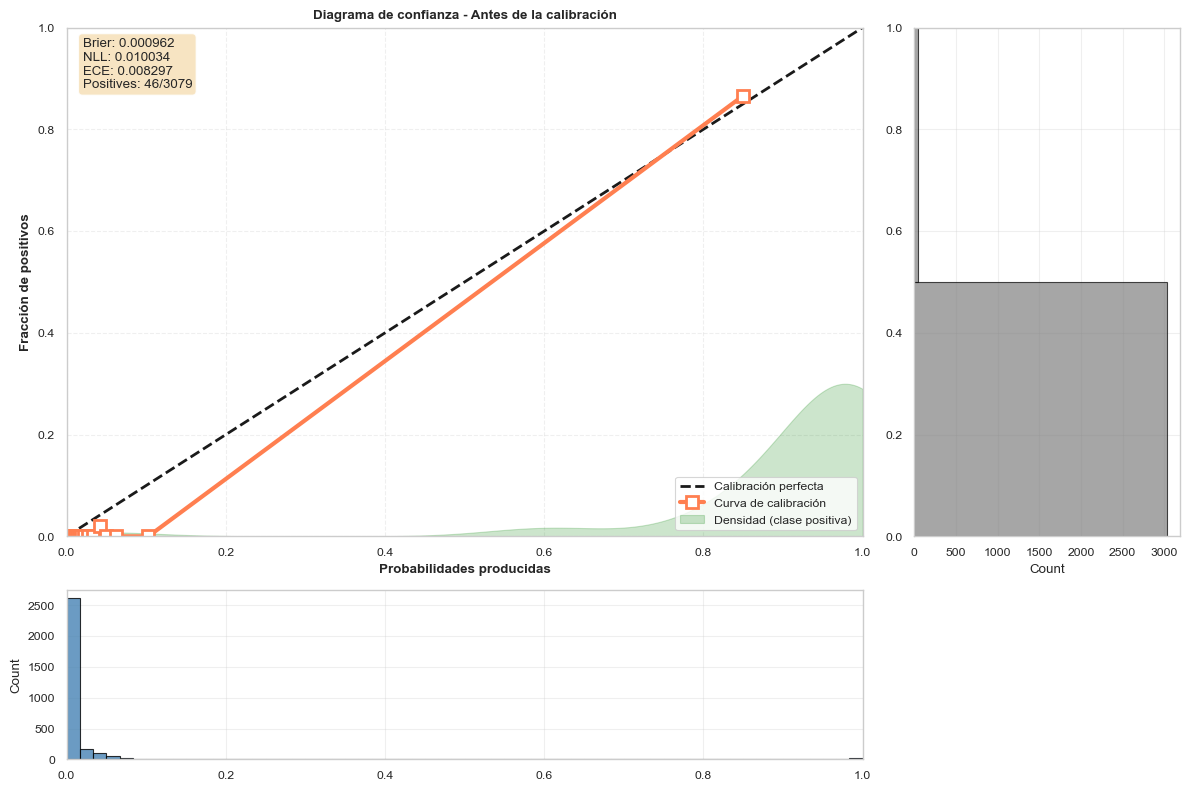

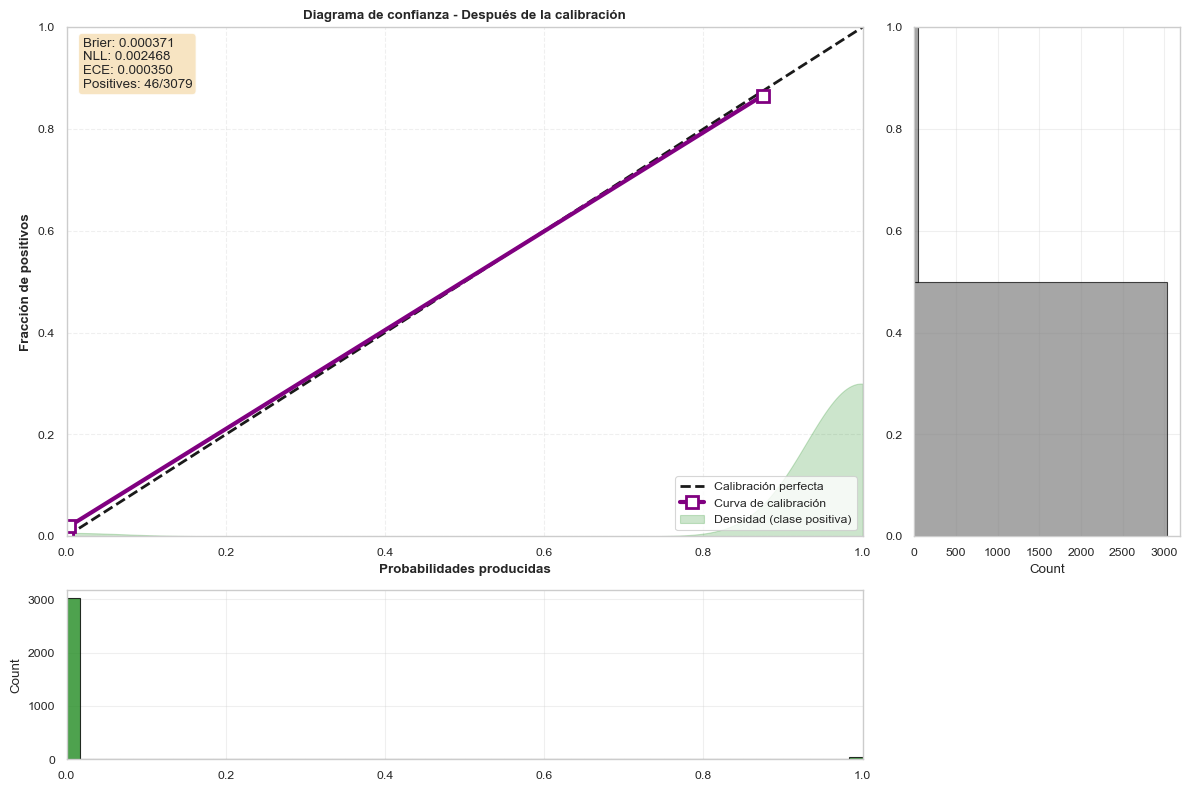

In [20]:
fig_before = plot_reliability_diagram(
    y_test.reshape((-1,)), t_pred,
    title="Diagrama de confianza - Antes de la calibración",
    n_bins=60,
    show_histogram=True,
    show_density=True,
    color='steelblue',
    calibration_color='coral'
)

fig_after = plot_reliability_diagram(
    y_test.reshape((-1,)), scaled_predictions,
    title="Diagrama de confianza - Después de la calibración",
    n_bins=60,
    show_histogram=True,
    show_density=True,
    color='forestgreen',
    calibration_color='purple'
)
plt.show()

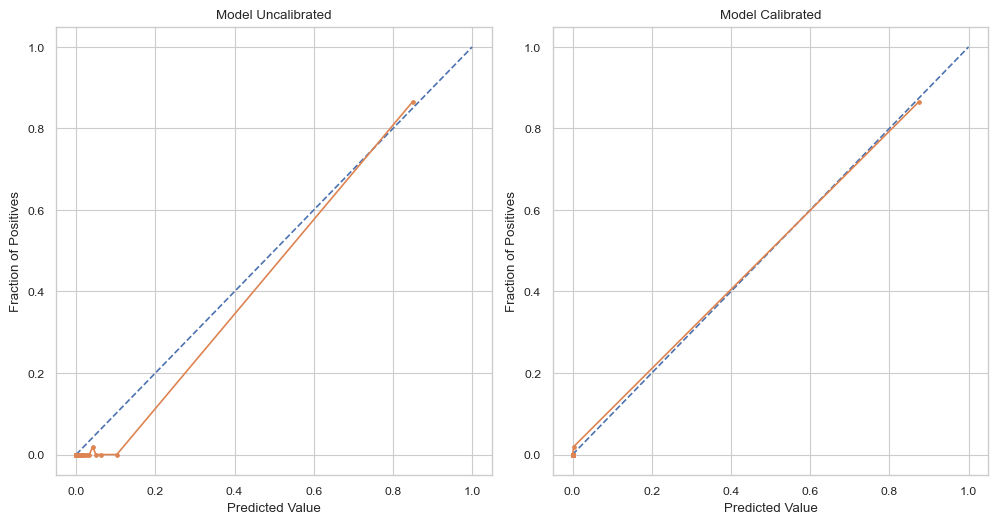

In [19]:
from sklearn.calibration import calibration_curve
def plot_calibration_curve(y, pred, cali_pred):
    plt.figure(figsize=(20, 20))
    plt.subplot(4, 4, 1)
    fraction_of_positives, mean_predicted_value = calibration_curve(y, pred, n_bins=60, strategy='quantile')
    plt.plot([0, 1], [0, 1], linestyle='--')
    plt.plot(mean_predicted_value, fraction_of_positives, marker='.')
    plt.xlabel("Predicted Value")
    plt.ylabel("Fraction of Positives")
    plt.title('Model Uncalibrated')
    

    plt.subplot(4, 4, 2)
    fraction_of_positives, mean_predicted_value = calibration_curve(y, cali_pred, n_bins=60, strategy='quantile')
    plt.plot([0, 1], [0, 1], linestyle='--')
    plt.plot(mean_predicted_value, fraction_of_positives, marker='.')
    plt.xlabel("Predicted Value")
    plt.ylabel("Fraction of Positives")
    plt.title('Model Calibrated')
    plt.tight_layout()
    plt.show()

plot_calibration_curve(y_test, t_pred, scaled_predictions)

In [43]:
y_test=y_test.reshape((-1,))

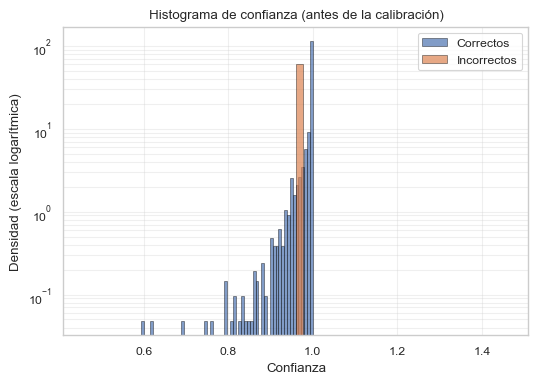

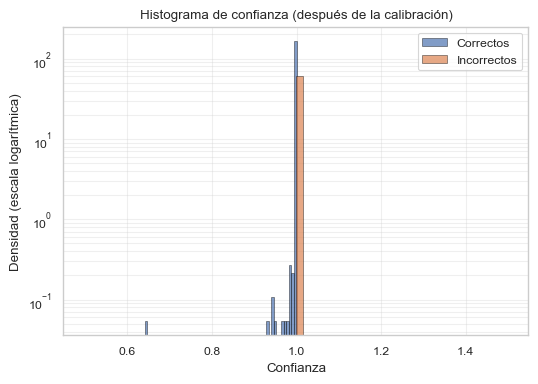

In [20]:
def plot_confidence_histogram(p, y_true=None, title="", bins=60):
    """
    p: array de probabilidades p(y=1|x)
    y_true: opcional, etiquetas reales para separar correctos/incorrectos
    """
    confidence = np.maximum(p, 1 - p)

    plt.figure(figsize=(6, 4))

    if y_true is None:
        plt.hist(confidence, bins=bins, density=True, alpha=0.8)
    else:
        preds = (p >= 0.5).astype(int)
        correct = preds == y_true

        plt.hist(confidence[correct], bins=bins, density=True,
                 alpha=0.7, label="Correctos", edgecolor="black", linewidth=0.4)
        plt.hist(confidence[~correct], bins=bins, density=True,
                 alpha=0.7, label="Incorrectos", edgecolor="black", linewidth=0.4)

        plt.legend()

    plt.xlabel("Confianza")
    plt.ylabel("Densidad (escala logarítmica)")
    plt.title(title)
    plt.yscale("log")
    plt.grid(True, alpha=0.3, which="both")
    plt.show()

plot_confidence_histogram(
    t_pred,
    y_test,
    title="Histograma de confianza (antes de la calibración)"
)
plot_confidence_histogram(
    scaled_predictions,
    y_test,
    title="Histograma de confianza (después de la calibración)"
)

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, brier_score_loss

def plot_confidence_histogram(
    y_true,
    y_pred_prob_positive,
    y_pred_labels=None,
    threshold=0.5,
    n_bins=10,
    model_name="Modelo"
):
    """
    Histograma de confianza: usa la confianza de la predicción realizada.

    Parámetros:
    -----------
    y_true : array
        Etiquetas verdaderas (0/1 o one-hot).
    y_pred_prob_positive : array
        - Binario: probabilidades de la clase positiva, o matriz (n,2) con [P(0), P(1)]
        - Multiclase: matriz (n,C) con probabilidades por clase
    y_pred_labels : array, opcional
        Etiquetas predichas. Si None, se calculan automáticamente.
    threshold : float
        Umbral para clasificación binaria cuando y_pred_labels es None y la salida es 1D.
    n_bins : int
        Número de intervalos para el histograma.
    model_name : str
        Nombre del modelo para el título.
    """

    y_true = np.asarray(y_true)
    y_pred_prob_positive = np.asarray(y_pred_prob_positive)

    # =========================
    # 1) NORMALIZACIÓN DE ENTRADAS
    # =========================

    # Etiquetas verdaderas
    if y_true.ndim > 1:
        if y_true.shape[1] == 1:
            y_true_labels = y_true.ravel().astype(int)
        else:
            y_true_labels = np.argmax(y_true, axis=1).astype(int)
    else:
        y_true_labels = y_true.astype(int)

    # Detectar binario vs multiclase
    # Binario si:
    # - salida 1D (probabilidad de clase positiva)
    # - o salida 2D con 1 o 2 columnas
    is_binary = (
        y_pred_prob_positive.ndim == 1
        or (y_pred_prob_positive.ndim == 2 and y_pred_prob_positive.shape[1] <= 2)
    )

    # =========================
    # 2) PREDICCIONES, CONFIANZA Y PROBABILIDADES PARA MÉTRICAS
    # =========================

    if is_binary:
        # Probabilidad de clase positiva
        if y_pred_prob_positive.ndim == 2:
            if y_pred_prob_positive.shape[1] == 2:
                p_pos = y_pred_prob_positive[:, 1]
                p_neg = y_pred_prob_positive[:, 0]
            else:  # shape (n,1)
                p_pos = y_pred_prob_positive[:, 0]
                p_neg = 1.0 - p_pos
        else:
            p_pos = y_pred_prob_positive.astype(float)
            p_neg = 1.0 - p_pos

        # Etiqueta predicha
        if y_pred_labels is None:
            if y_pred_prob_positive.ndim == 2 and y_pred_prob_positive.shape[1] == 2:
                y_pred_labels = np.argmax(y_pred_prob_positive, axis=1).astype(int)
            else:
                y_pred_labels = (p_pos >= threshold).astype(int)
        else:
            y_pred_labels = np.asarray(y_pred_labels)
            if y_pred_labels.ndim > 1:
                y_pred_labels = np.argmax(y_pred_labels, axis=1)
            y_pred_labels = y_pred_labels.astype(int)

        # Confianza de la predicción realizada:
        # P(\hat y|x) = p_pos si predice 1, 1-p_pos si predice 0
        confidence = np.where(y_pred_labels == 1, p_pos, p_neg)

        # En binario, la confianza top-label está en [0.5, 1]
        bins = np.linspace(0.5, 1.0, n_bins + 1)

        # Métricas de discriminación/calibración deben usar p_pos, no confidence
        try:
            AUC_ROC = roc_auc_score(y_true_labels, p_pos)
        except ValueError:
            AUC_ROC = np.nan

        try:
            brier_score = brier_score_loss(y_true_labels, p_pos)
        except ValueError:
            brier_score = np.nan

    else:
        # Multiclase
        if y_pred_labels is None:
            y_pred_labels = np.argmax(y_pred_prob_positive, axis=1).astype(int)
        else:
            y_pred_labels = np.asarray(y_pred_labels)
            if y_pred_labels.ndim > 1:
                y_pred_labels = np.argmax(y_pred_labels, axis=1)
            y_pred_labels = y_pred_labels.astype(int)

        # Confianza top-label: max_k p_k(x)
        confidence = np.max(y_pred_prob_positive, axis=1)
        bins = np.linspace(0.0, 1.0, n_bins + 1)

        # AUC macro OVR
        try:
            AUC_ROC = roc_auc_score(
                y_true_labels,
                y_pred_prob_positive,
                multi_class="ovr",
                average="macro"
            )
        except ValueError:
            AUC_ROC = np.nan

        # Brier multiclass: media del error cuadrático respecto a one-hot
        try:
            n_classes = y_pred_prob_positive.shape[1]
            y_true_onehot = np.eye(n_classes)[y_true_labels]
            brier_score = np.mean(np.sum((y_pred_prob_positive - y_true_onehot) ** 2, axis=1))
        except Exception:
            brier_score = np.nan

    # =========================
    # 3) CORRECTAS / INCORRECTAS
    # =========================

    correct = (y_pred_labels == y_true_labels)
    incorrect = ~correct

    # =========================
    # 4) HISTOGRAMA POR BINS
    # =========================

    bin_centers = (bins[:-1] + bins[1:]) / 2
    width = (bins[1] - bins[0]) * 0.38

    conf_correct = confidence[correct]
    conf_incorrect = confidence[incorrect]

    counts_correct, _ = np.histogram(conf_correct, bins=bins)
    counts_incorrect, _ = np.histogram(conf_incorrect, bins=bins)
    total_counts = counts_correct + counts_incorrect

    # =========================
    # 5) TASA DE ERROR POR BIN
    # =========================

    error_rate_by_bin = []
    n_samples_by_bin = []

    for i in range(n_bins):
        mask = (confidence >= bins[i]) & (confidence < bins[i + 1])
        if i == n_bins - 1:
            mask = (confidence >= bins[i]) & (confidence <= bins[i + 1])

        n_samples = np.sum(mask)
        n_samples_by_bin.append(n_samples)

        if n_samples > 0:
            error_rate = np.sum(y_pred_labels[mask] != y_true_labels[mask]) / n_samples
            error_rate_by_bin.append(error_rate)
        else:
            error_rate_by_bin.append(0.0)

    total_samples = len(y_true_labels)

    # =========================
    # 6) ECE SOBRE CONFIANZA TOP-LABEL
    # =========================

    def _confidence_ece(confidence_values, correct_mask, bin_edges):
        if len(confidence_values) == 0:
            return 0.0

        bin_ids = np.digitize(confidence_values, bin_edges, right=True) - 1
        bin_ids = np.clip(bin_ids, 0, len(bin_edges) - 2)

        ece_value = 0.0
        total = len(confidence_values)

        for b in range(len(bin_edges) - 1):
            mask = bin_ids == b
            if np.sum(mask) > 0:
                bin_acc = np.mean(correct_mask[mask])
                bin_conf = np.mean(confidence_values[mask])
                ece_value += (np.sum(mask) / total) * abs(bin_acc - bin_conf)

        return ece_value

    ece = _confidence_ece(confidence, correct, bins)

    # =========================
    # 7) ALTA CONFIANZA, DISTRIBUCIÓN Y RESUMEN
    # =========================

    high_conf_mask = confidence >= 0.9
    n_high_conf = np.sum(high_conf_mask)

    if n_high_conf > 0:
        high_conf_error_rate = np.sum(
            y_pred_labels[high_conf_mask] != y_true_labels[high_conf_mask]
        ) / n_high_conf
    else:
        high_conf_error_rate = 0.0

    low_conf = np.sum(confidence < 0.6) / total_samples if total_samples > 0 else 0.0
    medium_conf = np.sum((confidence >= 0.6) & (confidence < 0.8)) / total_samples if total_samples > 0 else 0.0
    high_conf = np.sum(confidence >= 0.8) / total_samples if total_samples > 0 else 0.0

    avg_conf_all = np.mean(confidence) if total_samples > 0 else 0.0
    avg_conf_correct = np.mean(confidence[correct]) if np.sum(correct) > 0 else 0.0
    avg_conf_incorrect = np.mean(confidence[incorrect]) if np.sum(incorrect) > 0 else 0.0

    # =========================
    # 8) GRÁFICO
    # =========================

    fig, axes = plt.subplots(2, 2, figsize=(15, 12))
    fig.suptitle(f'Histograma de Confianza - {model_name}',
                 fontsize=16, fontweight='bold')

    # SUBPLOT 1: HISTOGRAMA DE CONFIANZA
    ax1 = axes[0, 0]

    ax1.bar(bin_centers - width/2, counts_correct, width=width,
            alpha=0.7, label='Correctas', color='#2ecc71',
            edgecolor='black', linewidth=0.5)
    ax1.bar(bin_centers + width/2, counts_incorrect, width=width,
            alpha=0.7, label='Incorrectas', color='#e74c3c',
            edgecolor='black', linewidth=0.5)

    ax1.set_xlabel('Confianza del Modelo (max(P(clase)))', fontsize=12)
    ax1.set_ylabel('Número de Muestras', fontsize=12)
    ax1.set_title('Distribución de Confianza por Exactitud de Predicción', fontsize=14)
    ax1.legend(loc='upper left')
    ax1.grid(True, alpha=0.3, axis='y')
    ax1.set_xlim(bins[0], bins[-1])

    for i, (corr, incorr) in enumerate(zip(counts_correct, counts_incorrect)):
        total = corr + incorr
        if total > 0:
            percentage = corr / total
            ax1.text(
                bin_centers[i],
                max(corr, incorr) + max(total_counts) * 0.02 if np.max(total_counts) > 0 else 0.02,
                f'{percentage:.0%}',
                ha='center',
                fontsize=9,
                bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7)
            )

    ax1.axvline(x=0.5, color='gray', linestyle='--', alpha=0.5)

    # SUBPLOT 2: TASA DE ERROR POR NIVEL DE CONFIANZA
    ax2 = axes[0, 1]

    bars = ax2.bar(
        bin_centers,
        error_rate_by_bin,
        width=width*2,
        color=['#e74c3c' if rate > 0.5 else
               '#f39c12' if rate > 0.2 else
               '#2ecc71' for rate in error_rate_by_bin],
        edgecolor='black',
        linewidth=1
    )

    for i, (err_rate, n_samples) in enumerate(zip(error_rate_by_bin, n_samples_by_bin)):
        if err_rate > 0.5 and bins[i] > 0.8:
            bars[i].set_hatch('//')
            bars[i].set_linewidth(2)
            ax2.text(
                bin_centers[i],
                err_rate + 0.03,
                "⚠ PELIGRO",
                ha='center',
                fontsize=10,
                fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.2', facecolor='yellow', alpha=0.8)
            )

        if n_samples > 0:
            ax2.text(
                bin_centers[i],
                err_rate / 2,
                f'n={n_samples}',
                ha='center',
                fontsize=8,
                color='white',
                fontweight='bold'
            )

    ax2.set_xlabel('Intervalo de Confianza', fontsize=12)
    ax2.set_ylabel('Tasa de Error', fontsize=12)
    ax2.set_title('Tasa de Error por Nivel de Confianza', fontsize=14)
    ax2.grid(True, alpha=0.3, axis='y')
    ax2.set_ylim(0, 1)

    # SUBPLOT 3 Y 4: TEXTO
    ax3 = axes[1, 0]
    ax3.axis('off')
    ax4 = axes[1, 1]
    ax4.axis('off')

    high_conf_rate = (n_high_conf / total_samples) if total_samples > 0 else 0.0

    metrics_text = (
        f'RESUMEN DEL MODELO - CONFIANZA CORREGIDA\n{"="*45}\n\n'
        f'• AUC-ROC Score: {AUC_ROC:.2%}\n'
        f'• Brier Score: {brier_score:.4f}\n'
        f'• Expected Calibration Error (ECE): {ece:.4f}\n\n'

        f'CONFIANZA PROMEDIO\n{"="*20}\n'
        f'• Todas las muestras: {avg_conf_all:.3f}\n'
        f'• Predicciones CORRECTAS: {avg_conf_correct:.3f}\n'
        f'• Predicciones INCORRECTAS: {avg_conf_incorrect:.3f}\n'
        f'• Diferencia: {avg_conf_correct - avg_conf_incorrect:.3f}\n\n'

        f'DISTRIBUCIÓN DE CONFIANZA\n{"="*25}\n'
        f'• Baja (<0.6): {low_conf:.1%}\n'
        f'• Media (0.6-0.8): {medium_conf:.1%}\n'
        f'• Alta (>0.8): {high_conf:.1%}\n\n'

        f'ANÁLISIS DE RIESGO\n{"="*20}\n'
        f'• Error en alta confianza (>0.9): {high_conf_error_rate:.2%}\n'
        f'• Muestras de alta confianza: {n_high_conf} ({high_conf_rate:.1%})\n'
        f'• Máximo error tolerable: <5%\n'
    )

    if ece < 0.01:
        cal_grade = "★ EXCELENTE ★"
        cal_color = "green"
    elif ece < 0.05:
        cal_grade = "✓ BUENO"
        cal_color = "orange"
    elif ece < 0.1:
        cal_grade = "⚠ ACEPTABLE"
        cal_color = "darkorange"
    else:
        cal_grade = "✗ REQUIERE RECALIBRACIÓN"
        cal_color = "red"

    ax3.text(
        0.05, 0.95, metrics_text,
        transform=ax3.transAxes,
        fontsize=10,
        verticalalignment='top',
        fontfamily='monospace'
    )

    plt.tight_layout()
    plt.show()


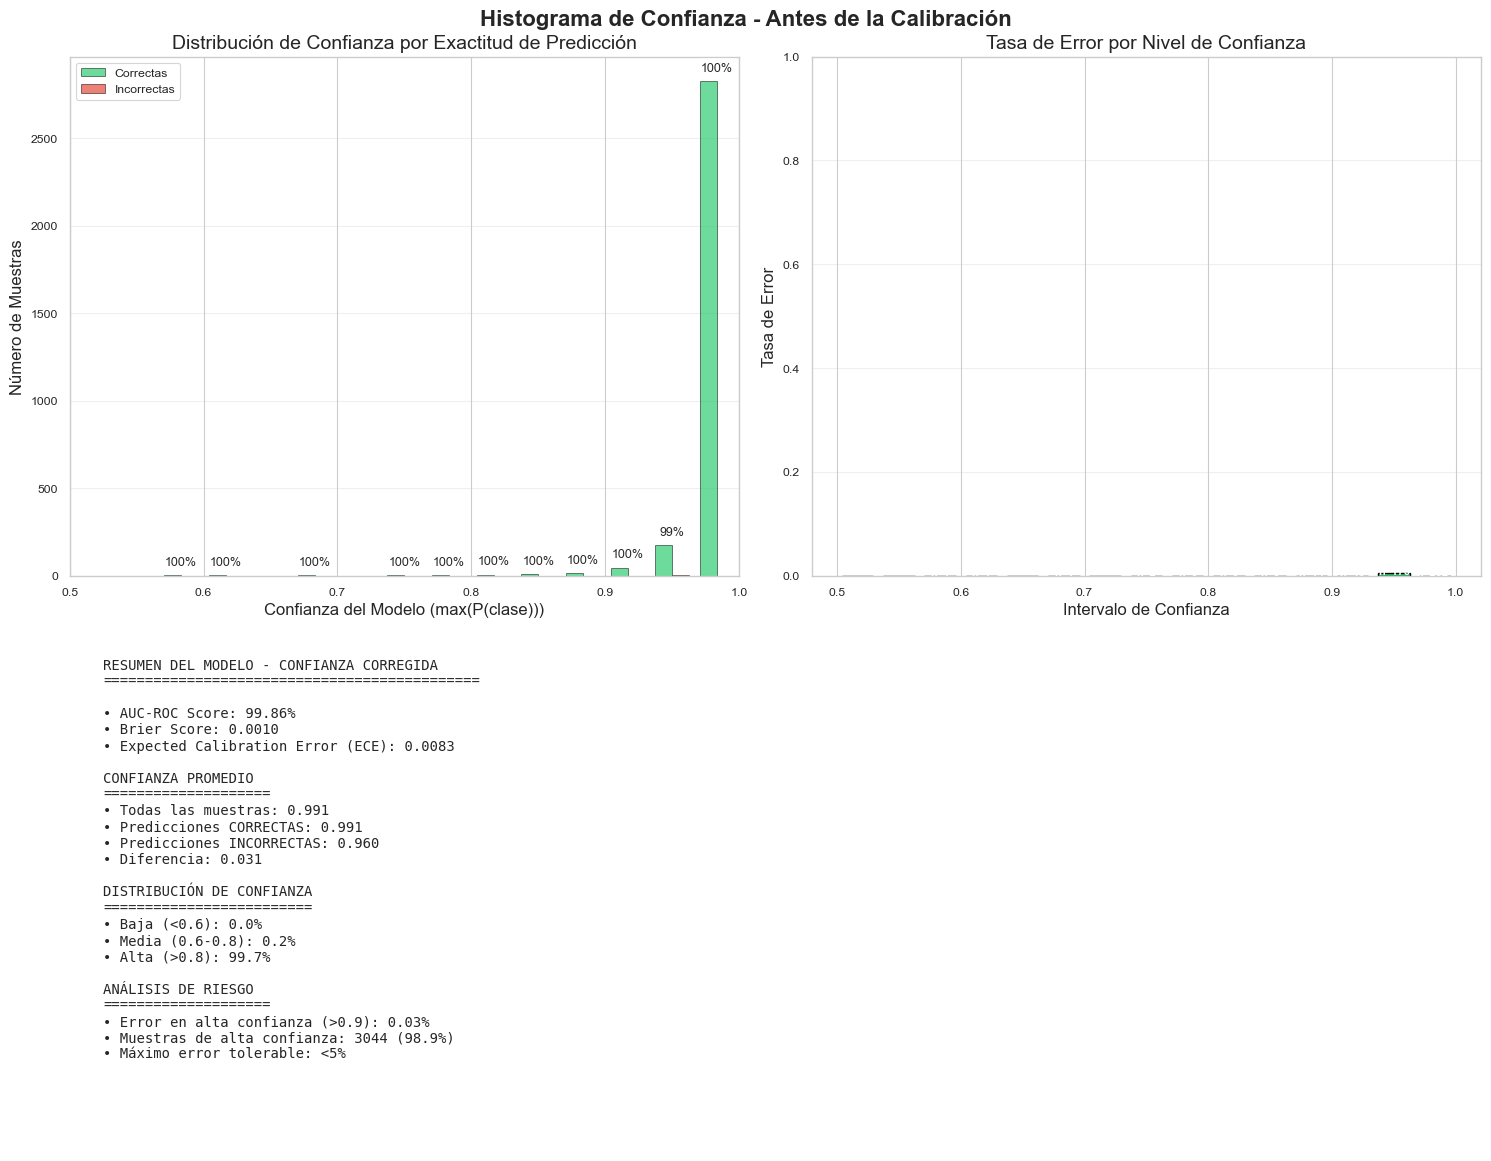

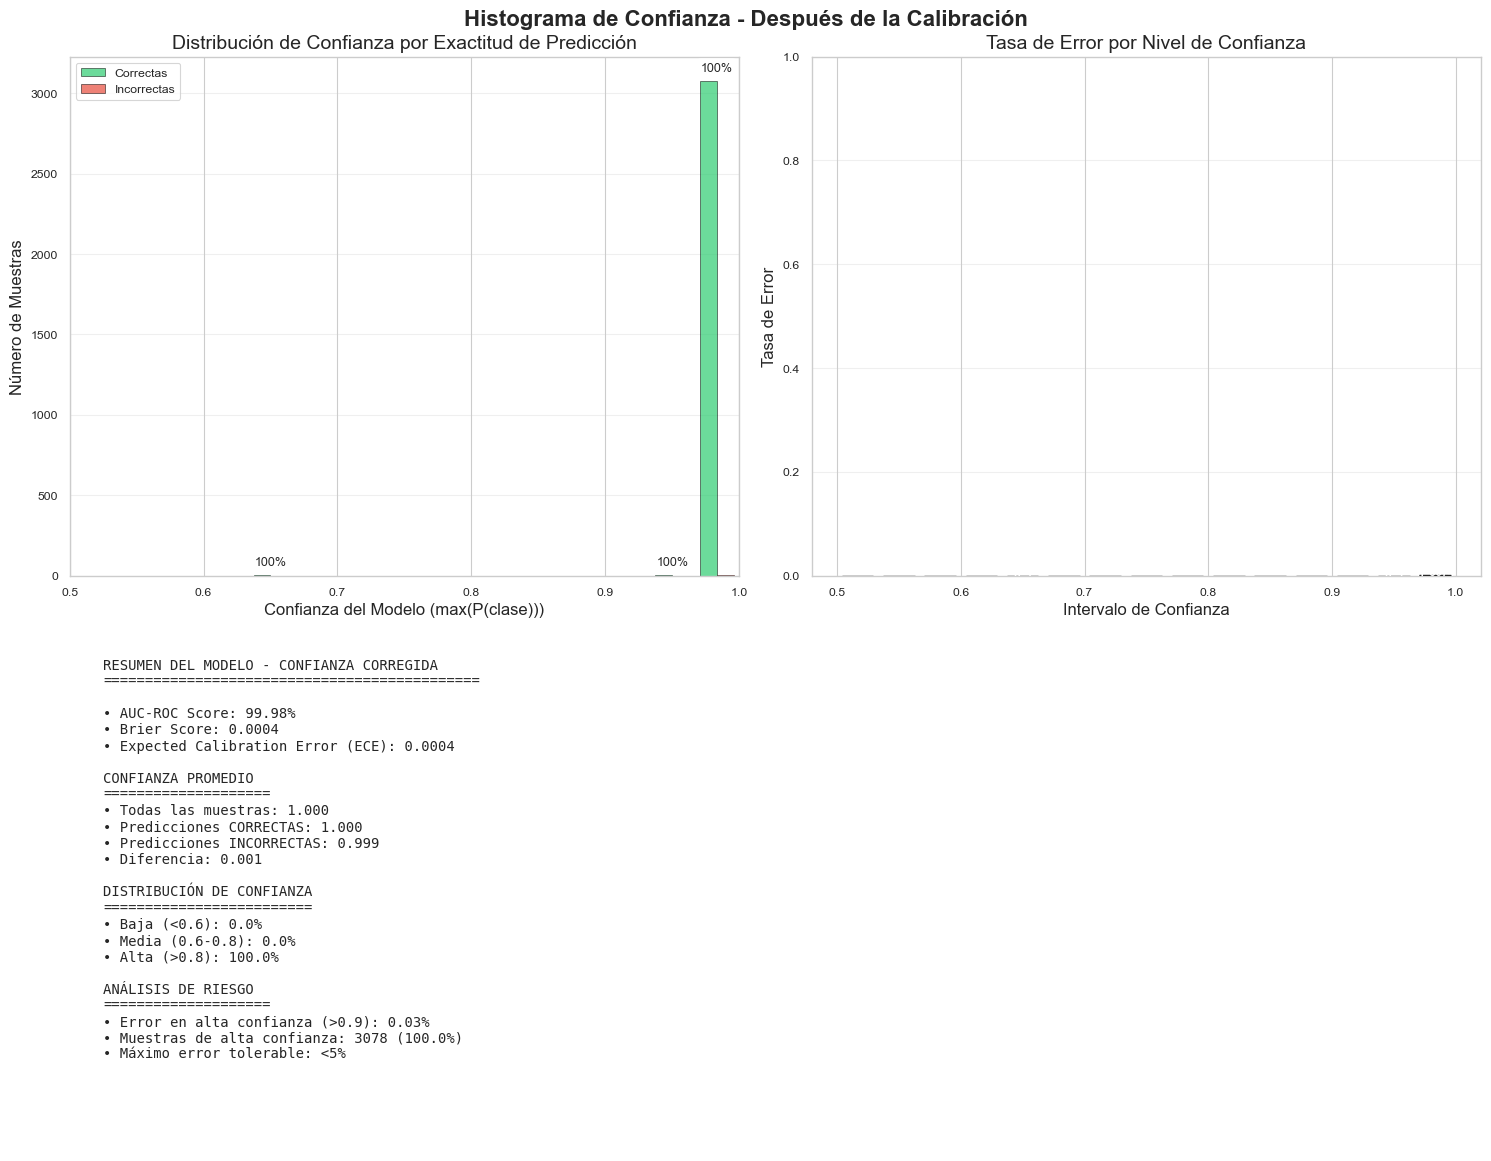

In [22]:
plot_confidence_histogram(y_test, t_pred, n_bins=15, model_name="Antes de la Calibración")
plot_confidence_histogram(y_test, scaled_predictions, n_bins=15, model_name="Después de la Calibración")

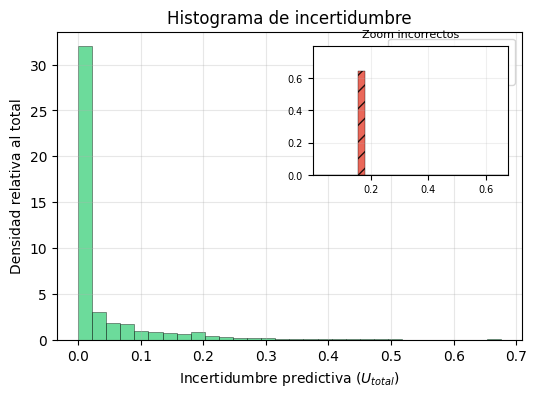

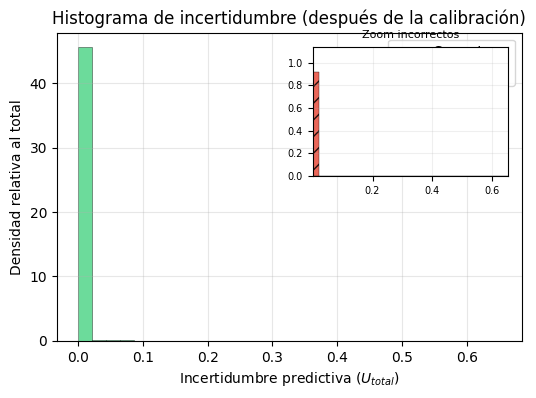

In [20]:
def plot_entropy_histogram(y_true, pred, title="", bins=30):
    entropy = binary_entropy(pred)
    preds = (pred >= 0.5).astype(int)
    correct = preds == y_true
    bin_edges = np.histogram_bin_edges(entropy, bins=bins)

    counts_correct, _ = np.histogram(entropy[correct], bins=bin_edges)
    counts_incorrect, _ = np.histogram(entropy[~correct], bins=bin_edges)
    total = max(len(entropy), 1)
    bin_widths = np.diff(bin_edges)

    correct_density = counts_correct / (total * bin_widths)
    incorrect_density = counts_incorrect / (total * bin_widths)

    fig, ax = plt.subplots(figsize=(6, 4))
    ax.bar(
        bin_edges[:-1],
        correct_density,
        width=bin_widths,
        align="edge",
        alpha=0.7,
        label="Correctos",
        color="#2ecc71",
        edgecolor="black",
        linewidth=0.4,
    )
    ax.bar(
        bin_edges[:-1],
        incorrect_density,
        width=bin_widths,
        align="edge",
        alpha=0.7,
        label="Incorrectos",
        color="#e74c3c",
        edgecolor="black",
        linewidth=0.4,
        hatch="//",
    )

    ax.set_xlabel("Incertidumbre predictiva ($U_{total}$)")
    ax.set_ylabel("Densidad relativa al total")
    ax.set_title(title)
    ax.legend()
    ax.grid(True, alpha=0.3)

    try:
        from mpl_toolkits.axes_grid1.inset_locator import inset_axes

        axins = inset_axes(ax, width="42%", height="42%", loc="upper right", borderpad=1)
        max_incorrect = float(incorrect_density.max()) if len(incorrect_density) else 0.0
        min_visible_height = max(max_incorrect * 0.15, float(correct_density.max()) * 0.02 if len(correct_density) else 0.0, 1e-12)
        incorrect_zoom = np.where(incorrect_density > 0, np.maximum(incorrect_density, min_visible_height), 0.0)
        axins.bar(
            bin_edges[:-1],
            incorrect_zoom,
            width=bin_widths,
            align="edge",
            alpha=0.85,
            color="#e74c3c",
            edgecolor="black",
            linewidth=0.3,
            hatch="//",
        )
        axins.set_title("Zoom incorrectos", fontsize=8)
        axins.set_xlim(bin_edges[0], bin_edges[-1])
        axins.set_ylim(0, max(float(incorrect_zoom.max()) * 1.25, min_visible_height * 1.25))
        axins.tick_params(axis="both", labelsize=7)
        axins.grid(True, alpha=0.2)
    except Exception:
        pass

    plt.show()
    return

plot_entropy_histogram(y_test, t_pred, title="Histograma de incertidumbre")
plot_entropy_histogram(y_test, scaled_predictions, title="Histograma de incertidumbre (después de la calibración)")

#### Análisis correlación entre incertidumbre y error

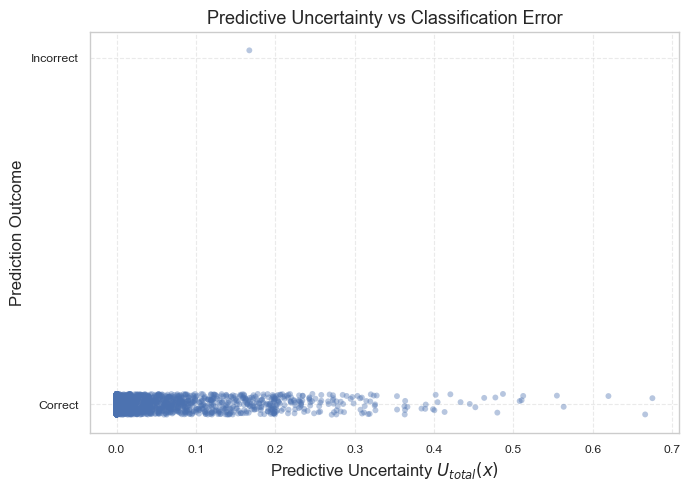

In [27]:
def plot_uncertainty_vs_error(
    u_total,
    y_true,
    p_mean,
    threshold=0.5,
    jitter=0.03,
    figsize=(7, 5)
):
    """
    Scatter plot: U_total vs error (paper-ready)

    Parameters
    ----------
    u_total : np.ndarray (N,)
        Predictive entropy per sample
    y_true : np.ndarray (N,)
        True binary labels
    p_mean : np.ndarray (N,)
        Marginal predicted probabilities
    threshold : float
        Decision threshold
    jitter : float
        Vertical jitter magnitude
    """

    # Binary predictions
    y_pred = (p_mean >= threshold).astype(int)

    # Error (0 = correct, 1 = incorrect)
    error = (y_pred != y_true).astype(int)

    # Add jitter for visualization
    error_jittered = error + np.random.uniform(
        low=-jitter, high=jitter, size=len(error)
    )

    plt.figure(figsize=figsize)

    plt.scatter(
        u_total,
        error_jittered,
        alpha=0.4,
        s=18,
        edgecolors="none"
    )

    plt.yticks([0, 1], ["Correct", "Incorrect"])
    plt.xlabel("Predictive Uncertainty $U_{total}(x)$", fontsize=12)
    plt.ylabel("Prediction Outcome", fontsize=12)

    plt.title(
        "Predictive Uncertainty vs Classification Error",
        fontsize=13
    )

    plt.grid(True, linestyle="--", alpha=0.4)
    plt.tight_layout()
    plt.show()
plot_uncertainty_vs_error(
    uncertainties[0].numpy(),  # U_total
    y_test,                    # True labels
    t_pred,       # p_mean
    threshold=0.5,
    jitter=0.03,
    figsize=(7, 5)
)

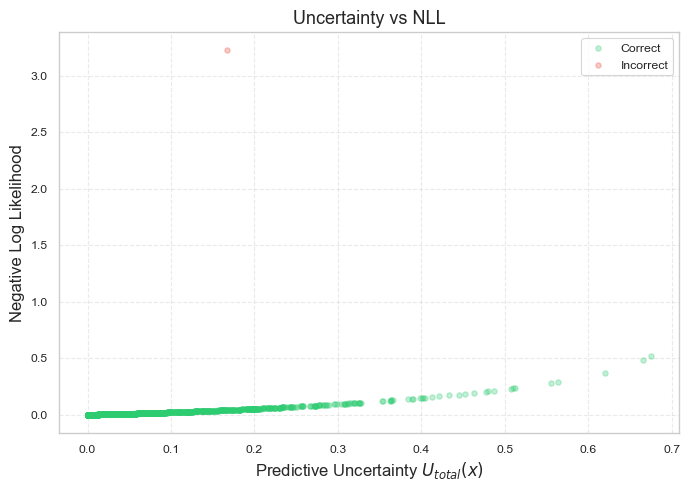

In [28]:
def plot_uncertainty_vs_nll(
    u_total,
    y_true,
    p_mean,
    x_label,
    y_label,
    title,
    n_bins=10,
    threshold=0.5,
    figsize=(7, 5)
):
    y_pred = (p_mean >= threshold).astype(int)
    loss = -(
        y_true * np.log(p_mean + 1e-8)
        + (1 - y_true) * np.log(1 - p_mean + 1e-8)
    )
    correct = (y_pred == y_true).astype(bool)
    incorrect = ~correct.astype(bool)

    # Scatter
    plt.figure(figsize=figsize)
    plt.scatter(
        u_total[correct],
        loss[correct],
        color='#2ecc71',
        alpha=0.3,
        s=15,
        label="Correct"
    )
    plt.scatter(
        u_total[incorrect],
        loss[incorrect],
        color='#e74c3c',
        alpha=0.3,
        s=15,
        label="Incorrect"
    )

    

    plt.xlabel(x_label, fontsize=12)
    plt.ylabel(y_label, fontsize=12)
    plt.title(title, fontsize=13)
    plt.legend()
    plt.grid(True, linestyle="--", alpha=0.4)
    plt.tight_layout()
    plt.show()

plot_uncertainty_vs_nll(
    uncertainties[0].numpy(),
    y_test,
    t_pred,
    x_label="Predictive Uncertainty $U_{total}(x)$",
    y_label="Negative Log Likelihood",
    title="Uncertainty vs NLL",
    n_bins=10,
    threshold=0.5,
    figsize=(7, 5)
)


In [29]:
from scipy.stats import spearmanr
loss = -(
    y_test * np.log(t_pred + 1e-7)
    + (1 - y_test) * np.log(1 - t_pred + 1e-7)
)
rho, p_value = spearmanr(uncertainties[0].numpy(), loss)
print(f"Spearman ρ = {rho:.3f}, p-value = {p_value:.2e}")

Spearman ρ = 0.992, p-value = 0.00e+00


In [14]:
import seaborn as sns

In [32]:
y_pred = (scaled_predictions >= 0.5).astype(int)

In [33]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score, classification_report
def plot_con_matrix(matrix, class_labels, title):  
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', cbar=True, square=True, linewidths=0.5, annot_kws={'size': 12})
    plt.xlabel('Prediccion')
    plt.ylabel('Valor Real')
    plt.title(title)
    plt.xticks(ticks=np.arange(len(class_labels)) + 0.5, labels=class_labels)
    plt.yticks(ticks=np.arange(len(class_labels)) + 0.5, labels=class_labels, rotation=0)
    plt.tight_layout()
    plt.show()

Accuracy test: 0.9997
Precision test: 1.0000
Recall test: 0.9783
AUC test: 0.9891
F1-score test: 0.9890
Clasification report test:
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00      3033
         1.0       1.00      0.98      0.99        46

    accuracy                           1.00      3079
   macro avg       1.00      0.99      0.99      3079
weighted avg       1.00      1.00      1.00      3079



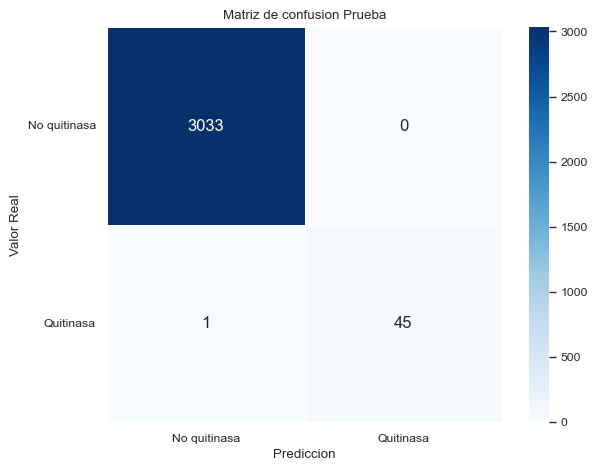

In [34]:
accuracy_v = accuracy_score(y_test, y_pred)
precision_v = precision_score(y_test, y_pred)
recall_v = recall_score(y_test, y_pred)
roc_auc_v = roc_auc_score(y_test, y_pred)
f1_v = f1_score(y_test, y_pred)
conf_matrix_v = confusion_matrix(y_test, y_pred)
print(f"Accuracy test: {accuracy_v:.4f}")
print(f"Precision test: {precision_v:.4f}")
print(f"Recall test: {recall_v:.4f}")
print(f'AUC test: {roc_auc_v:.4f}')
print(f"F1-score test: {f1_v:.4f}")
print("Clasification report test:", classification_report(y_test, y_pred), sep=f'\n')
class_labels = ['No quitinasa', 'Quitinasa']
plot_con_matrix(conf_matrix_v, class_labels, 'Matriz de confusion Prueba')

### Validar como aumentan las medidas de calidad a medida que se van eliminando las secuencias de más incertidumbre

In [35]:
u_total = uncertainties[0].numpy()

In [36]:
index = np.array([i for i in range(len(u_total))])
combined = np.concatenate((u_total.reshape(-1, 1), index.reshape(-1, 1)), axis=1)

In [37]:
sorted_u = combined[combined[:,0].argsort()[::-1]]

### Uncertainty Distribution by Class (Before Ablation)

In [ ]:
# Prepare class-specific indices sorted by uncertainty
pos_idx = np.where(y_test.ravel() == 1)[0]
neg_idx = np.where(y_test.ravel() == 0)[0]
# Sort within each class by uncertainty (descending)
pos_sorted_idx = pos_idx[np.argsort(u_total[pos_idx])[::-1]]
neg_sorted_idx = neg_idx[np.argsort(u_total[neg_idx])[::-1]]

print(f"Total positive samples: {len(pos_idx)}")
print(f"Total negative samples: {len(neg_idx)}")
print(f"Class imbalance ratio: {len(neg_idx)/len(pos_idx):.1f}:1")

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')


def plot_uncertainty_distribution_by_class(
    uncertainties,
    neg_sorted_idx,
    pos_sorted_idx,
    n_bins=10,
    class_names=None,
    figsize=(12, 5),
    cmap_counts=("#2c7fb8", "#feb24c")
):
    """Plot distribution of predictive uncertainty by class.

    - uncertainties: 1D array-like of predictive uncertainty (e.g. predictive entropy)
    - neg_sorted_idx, pos_sorted_idx: arrays of sample indices for negative and positive classes,
      sorted (optionally) by uncertainty if desired. Only used to select samples for each class.
    - n_bins: number of uncertainty intervals
    - class_names: list like ['Negative','Positive']

    The plot shows grouped bar counts per bin (absolute counts) and overlayed per-class
    percentages (relative to each class size) on a secondary y-axis. This highlights
    imbalance while showing how many positives/negatives fall in each uncertainty interval.
    """

    uncertainties = np.asarray(uncertainties).ravel()

    if class_names is None:
        class_names = ["Negative", "Positive"]

    # Select class-specific uncertainties
    u_neg = uncertainties[np.asarray(neg_sorted_idx).astype(int)]
    u_pos = uncertainties[np.asarray(pos_sorted_idx).astype(int)]

    # Bin edges computed from full range for consistent intervals
    bin_edges = np.linspace(uncertainties.min(), uncertainties.max(), n_bins + 1)
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

    # Counts per bin
    counts_neg, _ = np.histogram(u_neg, bins=bin_edges)
    counts_pos, _ = np.histogram(u_pos, bins=bin_edges)

    total_neg = len(u_neg)
    total_pos = len(u_pos)

    # Percent per class relative to class size
    perc_neg = (counts_neg / total_neg * 100) if total_neg > 0 else np.zeros_like(counts_neg)
    perc_pos = (counts_pos / total_pos * 100) if total_pos > 0 else np.zeros_like(counts_pos)

    width = (bin_centers[1] - bin_centers[0]) * 0.38 if n_bins > 1 else 0.02

    fig, ax1 = plt.subplots(figsize=figsize)

    # Bars: absolute counts
    bars_neg = ax1.bar(bin_centers - width/2, counts_neg, width=width, label=f"{class_names[0]} (count)", color=cmap_counts[0], edgecolor='black', alpha=0.9)
    bars_pos = ax1.bar(bin_centers + width/2, counts_pos, width=width, label=f"{class_names[1]} (count)", color=cmap_counts[1], edgecolor='black', alpha=0.9)

    ax1.set_xlabel('Uncertainty')
    ax1.set_ylabel('Count')
    ax1.set_title('Uncertainty Distribution by Class')
    ax1.grid(axis='y', alpha=0.4)

    # Secondary axis for percentage relative to each class
    ax2 = ax1.twinx()
    ax2.plot(bin_centers, perc_neg, color=cmap_counts[0], linestyle='--', marker='o', label=f"{class_names[0]} (% of class)")
    ax2.plot(bin_centers, perc_pos, color=cmap_counts[1], linestyle='--', marker='o', label=f"{class_names[1]} (% of class)")
    ax2.set_ylabel('Percent of Class (%)')

    # Legends: combine
    handles1, labels1 = ax1.get_legend_handles_labels()
    handles2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(handles1 + handles2, labels1 + labels2, loc='upper right')

    # Annotate bars with counts (small)
    def annotate_bars(bars):
        for b in bars:
            h = b.get_height()
            if h > 0:
                ax1.text(b.get_x() + b.get_width() / 2, h + max(1, h * 0.02), f"{int(h)}", ha='center', va='bottom', fontsize=8)

    annotate_bars(bars_neg)
    annotate_bars(bars_pos)

    # Add table-like text with class totals under the plot
    totals_text = f"Totals: {class_names[0]}={total_neg}, {class_names[1]}={total_pos}"
    plt.tight_layout()
    ax1.annotate(totals_text, xy=(0.01, -0.16), xycoords='axes fraction', fontsize=10, ha='left')

    return fig

In [ ]:

plot_uncertainty_distribution_by_class(
    u_total, 
    neg_sorted_idx, 
    pos_sorted_idx, 
    n_bins=15, 
    class_names=['Negative (No chitinase)', 'Positive (Chitinase)']
)

#### Para el 5%

In [38]:
percent = 5
total_r = int(len(sorted_u) * percent/100)
filter_index = sorted_u[total_r:, 1].astype(int)

In [39]:
filter_emb = X_test_emb[filter_index]
filter_feat = X_test_feat[filter_index]
y_filter = y_test[filter_index]

In [40]:
filtered = tf.data.Dataset.from_tensor_slices(
    (filter_emb.astype('float64'), filter_feat.astype('float64'))
).batch(64)

In [41]:
f_pred, f_logits, f_uncertainties = uq.predict_with_uncertainty(filtered)
f_pred = f_pred.numpy()
f_logits = f_logits.numpy()
f_scaled_predictions = lr_scaler.predict_proba(f_logits.astype('float32').reshape((-1, 1)))[:, 1]

In [42]:
y_pred_f = (f_scaled_predictions >= 0.5).astype(int)

Accuracy test: 0.9997
Precision test: 1.0000
Recall test: 0.9697
AUC test: 0.9848
F1-score test: 0.9846
Clasification report test:
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00      2893
         1.0       1.00      0.97      0.98        33

    accuracy                           1.00      2926
   macro avg       1.00      0.98      0.99      2926
weighted avg       1.00      1.00      1.00      2926



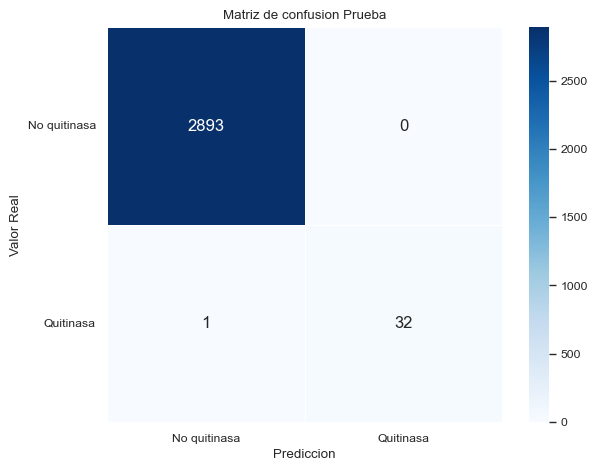

In [44]:
accuracy_v = accuracy_score(y_filter, y_pred_f)
precision_v = precision_score(y_filter, y_pred_f)
recall_v = recall_score(y_filter, y_pred_f)
roc_auc_v = roc_auc_score(y_filter, y_pred_f)
f1_v = f1_score(y_filter, y_pred_f)
conf_matrix_v = confusion_matrix(y_filter, y_pred_f)
print(f"Accuracy test: {accuracy_v:.4f}")
print(f"Precision test: {precision_v:.4f}")
print(f"Recall test: {recall_v:.4f}")
print(f'AUC test: {roc_auc_v:.4f}')
print(f"F1-score test: {f1_v:.4f}")
print("Clasification report test:", classification_report(y_filter, y_pred_f), sep=f'\n')
plot_con_matrix(conf_matrix_v, class_labels, 'Matriz de confusion Prueba')


#### Para el 10%

In [45]:
percent = 10
total_r = int(len(sorted_u) * percent/100)
filter_index = sorted_u[total_r:, 1].astype(int)

In [46]:
filter_emb = X_test_emb[filter_index]
filter_feat = X_test_feat[filter_index]
y_filter = y_test[filter_index]

In [47]:
filtered = tf.data.Dataset.from_tensor_slices(
    (filter_emb.astype('float64'), filter_feat.astype('float64'))
).batch(64)

In [48]:
f_pred, f_logits, f_uncertainties = uq.predict_with_uncertainty(filtered)
f_pred = f_pred.numpy()
f_logits = f_logits.numpy()
f_scaled_predictions = lr_scaler.predict_proba(f_logits.astype('float32').reshape((-1, 1)))[:, 1]

In [49]:
y_pred_f = (f_scaled_predictions >= 0.5).astype(int)

Accuracy test: 1.0000
Precision test: 1.0000
Recall test: 1.0000
AUC test: 1.0000
F1-score test: 1.0000
Clasification report test:
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00      2744
         1.0       1.00      1.00      1.00        28

    accuracy                           1.00      2772
   macro avg       1.00      1.00      1.00      2772
weighted avg       1.00      1.00      1.00      2772



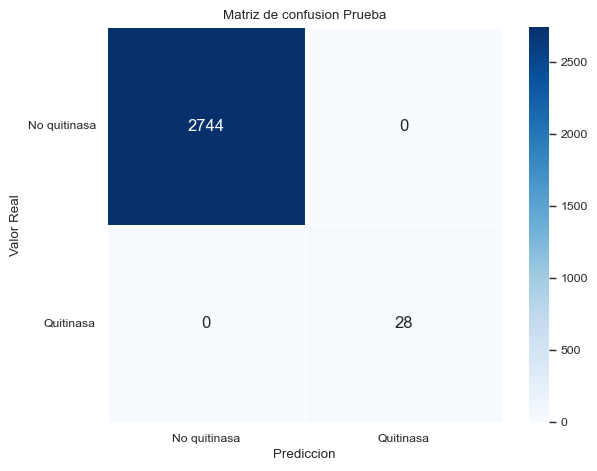

In [50]:
accuracy_v = accuracy_score(y_filter, y_pred_f)
precision_v = precision_score(y_filter, y_pred_f)
recall_v = recall_score(y_filter, y_pred_f)
roc_auc_v = roc_auc_score(y_filter, y_pred_f)
f1_v = f1_score(y_filter, y_pred_f)
conf_matrix_v = confusion_matrix(y_filter, y_pred_f)
print(f"Accuracy test: {accuracy_v:.4f}")
print(f"Precision test: {precision_v:.4f}")
print(f"Recall test: {recall_v:.4f}")
print(f'AUC test: {roc_auc_v:.4f}')
print(f"F1-score test: {f1_v:.4f}")
print("Clasification report test:", classification_report(y_filter, y_pred_f), sep=f'\n')
plot_con_matrix(conf_matrix_v, class_labels, 'Matriz de confusion Prueba')